# 1、Calculating cosine similarity

## Preparation

In [1]:
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable

from model.CSU_EI import CSUEI
from model.tokenizer import build_tokenizer
from data_provider.dataset import pre_processing_ms, pre_processing_smi

d:\Anaconda\envs\csu-ei\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Loading the model

In [2]:
with open("configs/config.json", 'r') as f:
        config_json = json.loads(f.read())
model_dict = torch.load("model_weight/CSU_EI_weight/trained_model_2024-09-16_113640add_ln1.pth", map_location=config_json["device"])
model = CSUEI(**config_json["model_config"])
model.load_state_dict(model_dict)
tokenizer = build_tokenizer(config_json['roberta_tokenizer_path'])

## Data Preprocessing

In [3]:
# Load data
df = pd.read_csv("data/example_data/7_test/smiles_peak_data.csv")
SMILES = df["smiles"].values
EIMS = df["spectra"].values

In [4]:
smiles_ids_list = []
smiles_mask_list = []
for smiles in SMILES:
    smiles_ids, smiles_mask = pre_processing_smi(smiles,tokenizer,config_json)
    smiles_ids_list.append(smiles_ids)
    smiles_mask_list.append(smiles_mask)

smiles_ids = torch.cat(smiles_ids_list, dim=0).to(config_json["device"])
smiles_mask = torch.cat(smiles_mask_list, dim=0).to(config_json["device"])

In [5]:
mz_list = []
intensity_list = []
ms_mask_list = []
for eims in EIMS:
    mz, intensity, ms_mask = pre_processing_ms(eims,config_json)
    mz_list.append(mz)
    intensity_list.append(intensity)
    ms_mask_list.append(ms_mask)

mz = torch.cat(mz_list, dim=0).to(config_json["device"])
intensity = torch.cat(intensity_list, dim=0).to(config_json["device"])
ms_mask = torch.cat(ms_mask_list, dim=0).to(config_json["device"])

## Building features

In [6]:
with torch.no_grad():
    model.to(config_json["device"])
    model.eval()
    smiles_feature, smiles_score = model.smiles_encoder([smiles_ids, smiles_mask])
    ms_feature, ms_score = model.ms_encoder([mz, intensity, ms_mask])

## Calculating cosine similarity

In [9]:
smiles_feature /= torch.norm(smiles_feature, dim=-1, keepdim=True)
ms_feature /= torch.norm(ms_feature, dim=-1, keepdim=True)
similarity = smiles_feature.cpu().numpy() @ ms_feature.cpu().numpy().T

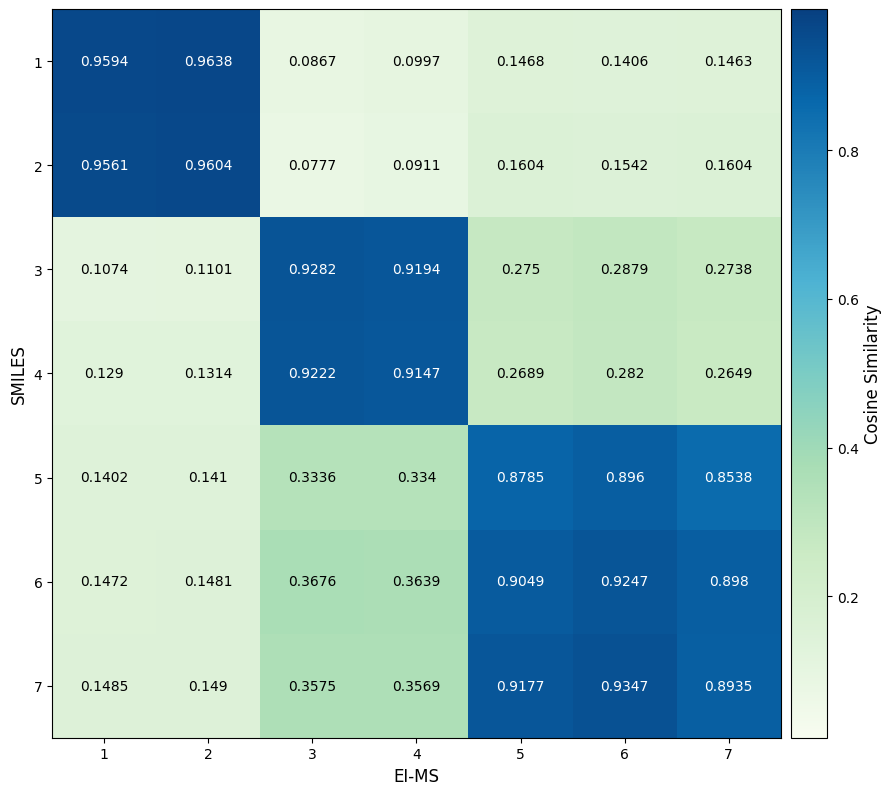

In [10]:
fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest')

norm = Normalize(vmin=0.01, vmax=0.99)
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest', norm=norm)

for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        color = "white" if similarity[i, j] > 0.5 else "black"
        ax.text(j, i, np.round(similarity[i, j], 4), ha="center", va="center", color=color, fontsize=10)

ax.set_xticks(range(similarity.shape[1]))
ax.set_xticklabels(range(1, similarity.shape[1] + 1))
ax.set_yticks(range(similarity.shape[0]))
ax.set_yticklabels(range(1, similarity.shape[0] + 1))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

ax.set_xlabel('EI-MS', fontsize=12)
ax.set_ylabel('SMILES', fontsize=12)

# plt.savefig("fig/7_smi_ms_similarity_matrix.png", dpi=300)
plt.show()


# 2、Cross-modal Retrieval between EI-MS and SMILES 

## SMIELS database(110 examples)

In [29]:
# example data "data/100_validations/100_val_smiles.csv"
# Load data
import pandas as pd
df = pd.read_csv("data/example_data/example_smiles_db/110_smiles.csv")
SMILES_110 = df["smiles"].values
smiles_ids_list = []
smiles_mask_list = []
for smiles in SMILES_110:
    smiles_ids, smiles_mask = pre_processing_smi(smiles,tokenizer,config_json)
    smiles_ids_list.append(smiles_ids)
    smiles_mask_list.append(smiles_mask)

smiles_ids = torch.cat(smiles_ids_list, dim=0).to(config_json["device"])
smiles_mask = torch.cat(smiles_mask_list, dim=0).to(config_json["device"])

In [30]:
with torch.no_grad():
    model.eval()
    smiles_feature_db, smiles_score_db = model.smiles_encoder([smiles_ids, smiles_mask])
smiles_feature_db /= torch.norm(smiles_feature_db, dim=-1, keepdim=True) # 110 x 768

similarity_db = ms_feature @ smiles_feature_db.T  # 10 x 110
top_sim, top_smi = similarity_db.cpu().topk(5, dim=-1)
print(top_sim)
print(top_smi)

tensor([[0.9563, 0.2665, 0.1858, 0.1756, 0.1724],
        [0.9018, 0.3825, 0.3736, 0.2899, 0.2621],
        [0.9479, 0.5938, 0.5382, 0.3268, 0.2388],
        [0.9652, 0.5236, 0.2251, 0.2206, 0.2070],
        [0.9277, 0.2154, 0.2140, 0.2138, 0.1906],
        [0.9400, 0.3882, 0.2713, 0.1806, 0.1677],
        [0.9343, 0.1638, 0.1370, 0.1309, 0.1257],
        [0.8924, 0.2066, 0.1543, 0.1411, 0.1185],
        [0.9389, 0.4322, 0.2839, 0.1994, 0.1656],
        [0.7245, 0.2687, 0.1540, 0.1352, 0.1279]])
tensor([[100,   6,  64, 104,  96],
        [101, 103,  23,  37,   6],
        [102,  97,  85,  27,  79],
        [103, 101,  22,  75,  44],
        [104,  83, 106,  85,  80],
        [105, 108, 104,  24,   8],
        [106, 107,  75, 104,  40],
        [107,  87,  98, 106, 101],
        [108, 105,  80, 106,   8],
        [109,  98,  75,  77,  81]])


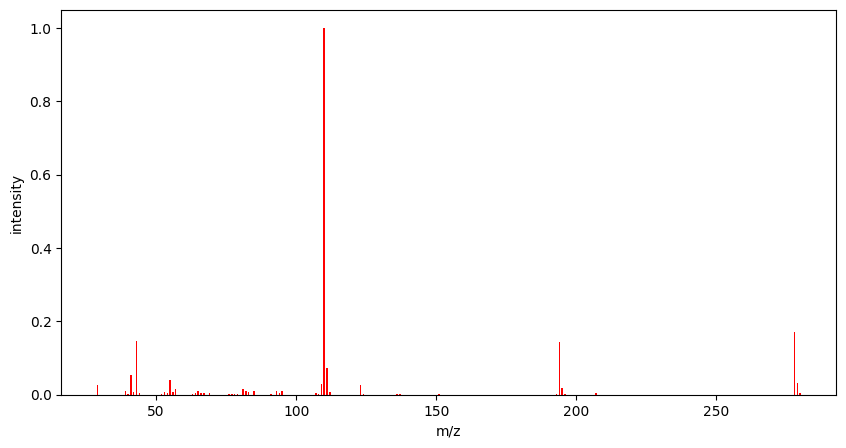

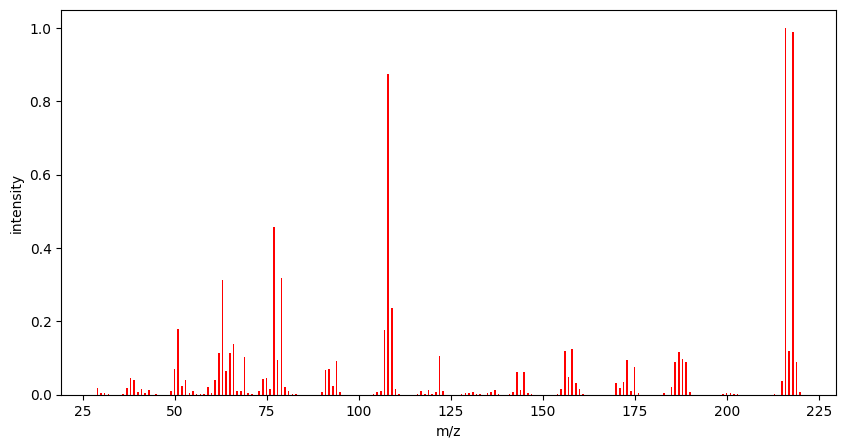

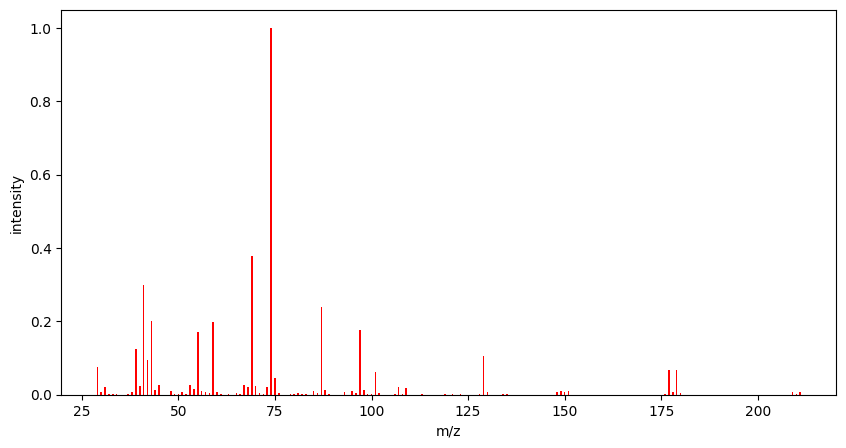

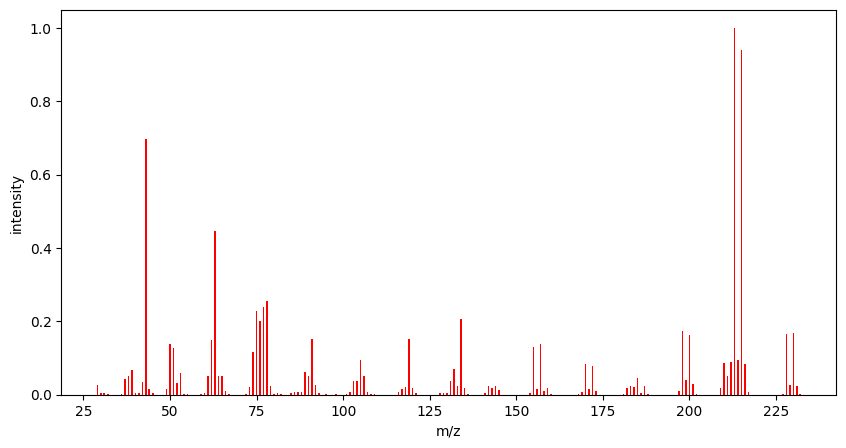

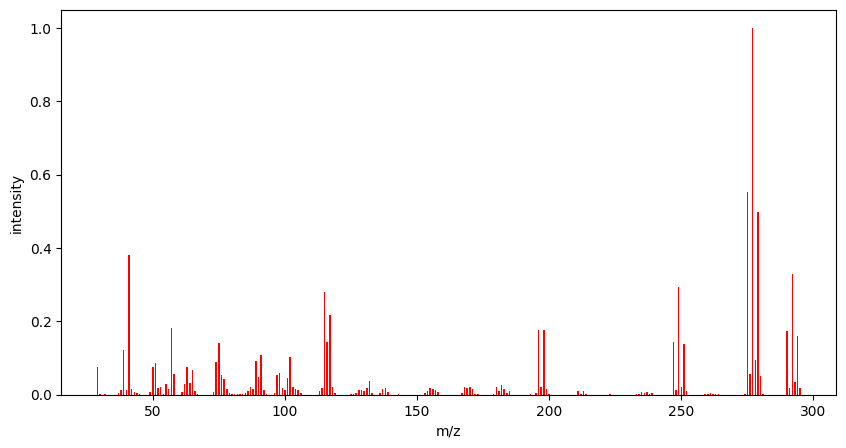

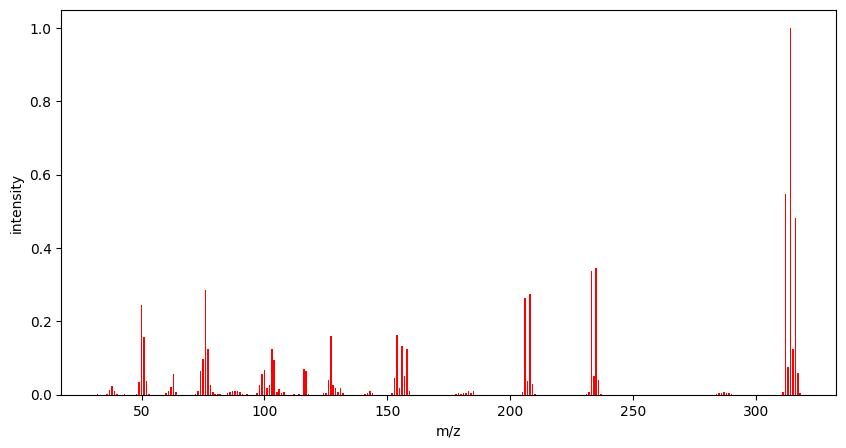

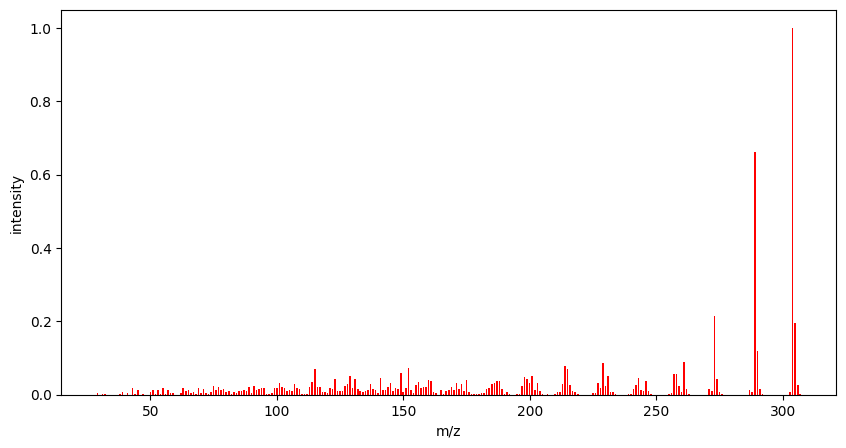

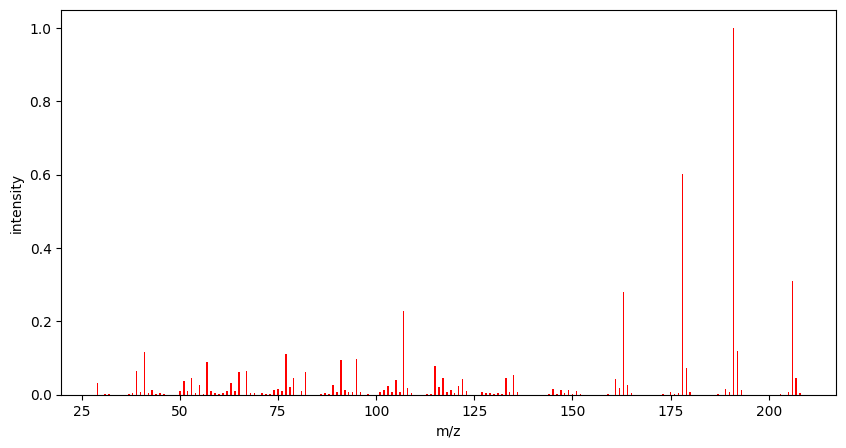

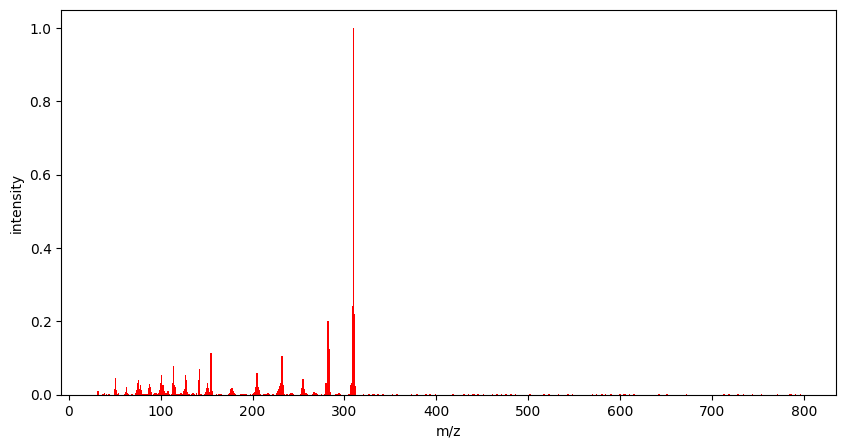

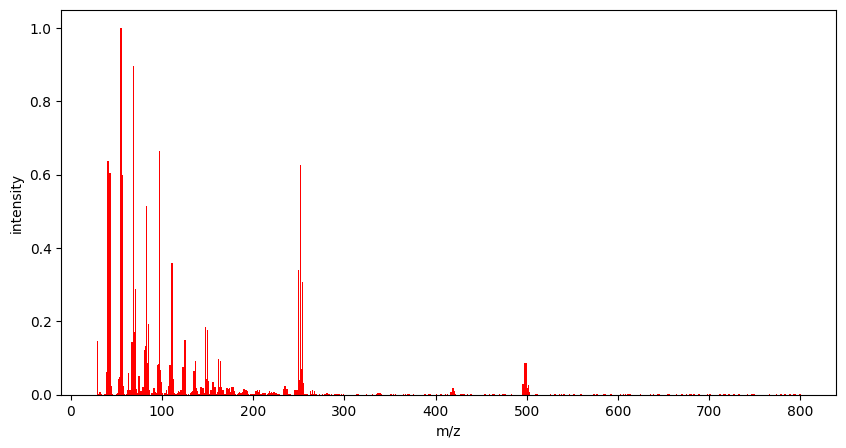

In [31]:
from utils.plot_eims import plot_ms_spectrum
for i in range(10):
    plot_ms_spectrum(EIMS[i])
    print(f"Top5 SMILES for EI-MS {i+1}:")
    for j in range(5):
        print(f"SMILES {j+1}: {SMILES_110[top_smi[i][j]]}, Similarity: {top_sim[i][j].item()}")
    

# 3、Visualization and Explainability

In [1]:
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable

from model.CSU_EI import CSUEI
from model.tokenizer import build_tokenizer
from data_provider.dataset import pre_processing_ms, pre_processing_smi, get_tokenined_smiles

d:\Anaconda\envs\csu-ei\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
with open("configs/config.json", 'r') as f:
        config_json = json.loads(f.read())
model_dict = torch.load("model_weight/CSU_EI_weight/trained_model_2024-09-16_113640add_ln1.pth", map_location=config_json["device"])
model = CSUEI(**config_json["model_config"])
model.load_state_dict(model_dict)
tokenizer = build_tokenizer(config_json['roberta_tokenizer_path'])

In [3]:
smiles = "BrCCCCCCCCCCCCOc1cc(Br)cc(Br)c1"
eims = "[[29.0, 0.1472], [30.0, 0.0025], [31.0, 0.0015], [32.0, 0.008100000000000001], [33.0, 0.0013], [37.0, 0.0021], [38.0, 0.0032], [39.0, 0.0617], [40.0, 0.0163], [41.0, 0.6378], [42.0, 0.0906], [43.0, 0.605], [44.0, 0.0231], [45.0, 0.0014000000000000002], [50.0, 0.0033], [51.0, 0.0043], [52.0, 0.0042], [53.0, 0.04190000000000001], [54.0, 0.0489], [55.0, 1.0], [56.0, 0.1527], [57.0, 0.5991], [58.0, 0.024300000000000002], [59.0, 0.0012], [61.0, 0.0024], [62.0, 0.0121], [63.0, 0.0605], [64.0, 0.011399999999999999], [65.0, 0.0121], [66.0, 0.0113], [67.0, 0.14400000000000002], [68.0, 0.0852], [69.0, 0.8974], [70.0, 0.1698], [71.0, 0.2891], [72.0, 0.0167], [73.0, 0.0039000000000000003], [74.0, 0.0126], [75.0, 0.0521], [76.0, 0.0073], [77.0, 0.010700000000000001], [78.0, 0.005], [79.0, 0.020499999999999997], [80.0, 0.0125], [81.0, 0.122], [82.0, 0.13390000000000002], [83.0, 0.5152], [84.0, 0.0873], [85.0, 0.1941], [86.0, 0.013999999999999999], [89.0, 0.0034000000000000002], [90.0, 0.0032], [91.0, 0.017], [92.0, 0.0055000000000000005], [93.0, 0.0085], [94.0, 0.005], [95.0, 0.0808], [96.0, 0.08439999999999999], [97.0, 0.6647], [98.0, 0.0676], [99.0, 0.0339], [100.0, 0.0034000000000000002], [103.0, 0.0042], [104.0, 0.0043], [105.0, 0.0121], [106.0, 0.0031], [107.0, 0.0229], [108.0, 0.0034999999999999996], [109.0, 0.0816], [110.0, 0.045599999999999995], [111.0, 0.3592], [112.0, 0.0429], [113.0, 0.005600000000000001], [115.0, 0.0018], [116.0, 0.0016], [117.0, 0.0058], [118.0, 0.0095], [119.0, 0.008100000000000001], [120.0, 0.0039000000000000003], [121.0, 0.0134], [122.0, 0.0014000000000000002], [123.0, 0.0745], [124.0, 0.031400000000000004], [125.0, 0.1493], [126.0, 0.0166], [127.0, 0.0022], [129.0, 0.0016], [131.0, 0.0058], [132.0, 0.0058], [133.0, 0.0074], [134.0, 0.0106], [135.0, 0.065], [136.0, 0.0098], [137.0, 0.0929], [138.0, 0.019], [139.0, 0.0098], [140.0, 0.0033], [141.0, 0.0029], [142.0, 0.003], [143.0, 0.0199], [144.0, 0.0055000000000000005], [145.0, 0.0192], [146.0, 0.0045000000000000005], [147.0, 0.006], [148.0, 0.18350000000000002], [149.0, 0.04190000000000001], [150.0, 0.177], [151.0, 0.036699999999999997], [152.0, 0.0022], [153.0, 0.0049], [154.0, 0.013999999999999999], [155.0, 0.0084], [156.0, 0.0349], [157.0, 0.006], [158.0, 0.02], [159.0, 0.0028000000000000004], [160.0, 0.0019], [161.0, 0.0063], [162.0, 0.0968], [163.0, 0.0215], [164.0, 0.0909], [165.0, 0.0203], [166.0, 0.012], [167.0, 0.013000000000000001], [168.0, 0.0028000000000000004], [169.0, 0.0024], [170.0, 0.0026], [171.0, 0.0172], [172.0, 0.0194], [173.0, 0.0168], [174.0, 0.0178], [175.0, 0.008199999999999999], [176.0, 0.0206], [177.0, 0.018000000000000002], [178.0, 0.019799999999999998], [179.0, 0.0106], [180.0, 0.0022], [183.0, 0.0019], [184.0, 0.006], [185.0, 0.0060999999999999995], [186.0, 0.0051], [187.0, 0.0052], [188.0, 0.0036], [189.0, 0.0069], [190.0, 0.0152], [191.0, 0.0141], [192.0, 0.013000000000000001], [193.0, 0.0104], [194.0, 0.0012], [195.0, 0.0011], [197.0, 0.0023], [198.0, 0.0016], [199.0, 0.0027], [200.0, 0.0014000000000000002], [201.0, 0.0015], [202.0, 0.0031], [203.0, 0.0104], [204.0, 0.008], [205.0, 0.013600000000000001], [206.0, 0.0072], [207.0, 0.0123], [208.0, 0.0025], [209.0, 0.0026], [211.0, 0.0045000000000000005], [212.0, 0.0022], [213.0, 0.0036], [216.0, 0.0012], [217.0, 0.004699999999999999], [218.0, 0.0088], [219.0, 0.0053], [220.0, 0.0074], [221.0, 0.0042], [222.0, 0.0025], [223.0, 0.0072], [224.0, 0.0043], [225.0, 0.004], [226.0, 0.0024], [227.0, 0.0022], [228.0, 0.0017000000000000001], [229.0, 0.0014000000000000002], [233.0, 0.0144], [234.0, 0.0021], [235.0, 0.0248], [236.0, 0.0028000000000000004], [237.0, 0.0144], [238.0, 0.0025], [239.0, 0.0024], [240.0, 0.0011], [241.0, 0.0013], [246.0, 0.013600000000000001], [247.0, 0.003], [248.0, 0.013300000000000001], [249.0, 0.0037], [250.0, 0.34119999999999995], [251.0, 0.0401], [252.0, 0.6261], [253.0, 0.0695], [254.0, 0.3079], [255.0, 0.031400000000000004], [256.0, 0.0031], [257.0, 0.0016], [259.0, 0.0013], [263.0, 0.009399999999999999], [264.0, 0.0017000000000000001], [265.0, 0.0134], [266.0, 0.0017000000000000001], [267.0, 0.0091], [268.0, 0.0017000000000000001], [269.0, 0.0011], [273.0, 0.0012], [276.0, 0.0024], [278.0, 0.0024], [279.0, 0.0011], [280.0, 0.0014000000000000002], [281.0, 0.0034000000000000002], [282.0, 0.0018], [283.0, 0.0025], [286.0, 0.0019], [289.0, 0.0013], [291.0, 0.0014000000000000002], [293.0, 0.0015], [294.0, 0.0013], [297.0, 0.0016], [299.0, 0.0013], [314.0, 0.0011], [315.0, 0.0016], [324.0, 0.0011], [331.0, 0.0012], [335.0, 0.0014000000000000002], [337.0, 0.0039000000000000003], [338.0, 0.0025], [339.0, 0.0049], [340.0, 0.0033], [341.0, 0.0012], [351.0, 0.0013], [354.0, 0.0011], [356.0, 0.0014000000000000002], [365.0, 0.0012], [367.0, 0.0017000000000000001], [369.0, 0.0011], [371.0, 0.0011], [376.0, 0.0016], [388.0, 0.0012], [389.0, 0.0013], [392.0, 0.0011], [394.0, 0.0013], [401.0, 0.0019], [406.0, 0.0012], [411.0, 0.0011], [413.0, 0.0011], [417.0, 0.008100000000000001], [418.0, 0.0018], [419.0, 0.0182], [420.0, 0.0043], [421.0, 0.0091], [422.0, 0.0028000000000000004], [428.0, 0.0014000000000000002], [429.0, 0.0015], [431.0, 0.0012], [435.0, 0.0011], [439.0, 0.0016], [454.0, 0.0014000000000000002], [459.0, 0.0011], [463.0, 0.0016], [464.0, 0.0011], [470.0, 0.0011], [474.0, 0.0013], [476.0, 0.0011], [483.0, 0.0016], [496.0, 0.0305], [497.0, 0.0066], [498.0, 0.0867], [499.0, 0.018600000000000002], [500.0, 0.087], [501.0, 0.018000000000000002], [502.0, 0.0276], [503.0, 0.0062], [510.0, 0.0014000000000000002], [511.0, 0.0012], [526.0, 0.002], [531.0, 0.0014000000000000002], [536.0, 0.0015], [538.0, 0.0011], [541.0, 0.0012], [547.0, 0.0012], [552.0, 0.0012], [559.0, 0.0011], [560.0, 0.0015], [574.0, 0.0015], [577.0, 0.0011], [584.0, 0.0017000000000000001], [586.0, 0.0012], [592.0, 0.0013], [593.0, 0.0013], [603.0, 0.0011], [606.0, 0.0019], [608.0, 0.0016], [611.0, 0.0011], [613.0, 0.0018], [625.0, 0.0011], [636.0, 0.0011], [639.0, 0.0012], [644.0, 0.0011], [645.0, 0.0019], [655.0, 0.0015], [656.0, 0.0013], [664.0, 0.0019], [670.0, 0.0015], [675.0, 0.0014000000000000002], [679.0, 0.0016], [680.0, 0.0013], [683.0, 0.0014000000000000002], [684.0, 0.0014000000000000002], [689.0, 0.0012], [698.0, 0.0013], [701.0, 0.0012], [712.0, 0.0014000000000000002], [716.0, 0.0012], [717.0, 0.0011], [718.0, 0.0012], [721.0, 0.0011], [722.0, 0.0012], [727.0, 0.0017000000000000001], [728.0, 0.0015], [733.0, 0.0013], [742.0, 0.0017000000000000001], [747.0, 0.0014000000000000002], [749.0, 0.0012], [750.0, 0.0012], [766.0, 0.0012], [774.0, 0.0017000000000000001], [779.0, 0.0016], [783.0, 0.0011], [788.0, 0.0012], [789.0, 0.0016], [793.0, 0.0015], [794.0, 0.0015], [799.0, 0.0011], [800.0, 0.0011]]"
smiles_ids, smiles_mask = pre_processing_smi(smiles,tokenizer,config_json)
mz, intensity, ms_mask = pre_processing_ms(eims,config_json)
with torch.no_grad():
    model.eval()
    smiles_feature, smiles_score = model.smiles_encoder([smiles_ids, smiles_mask])
    ms_feature, ms_score = model.ms_encoder([mz, intensity, ms_mask])


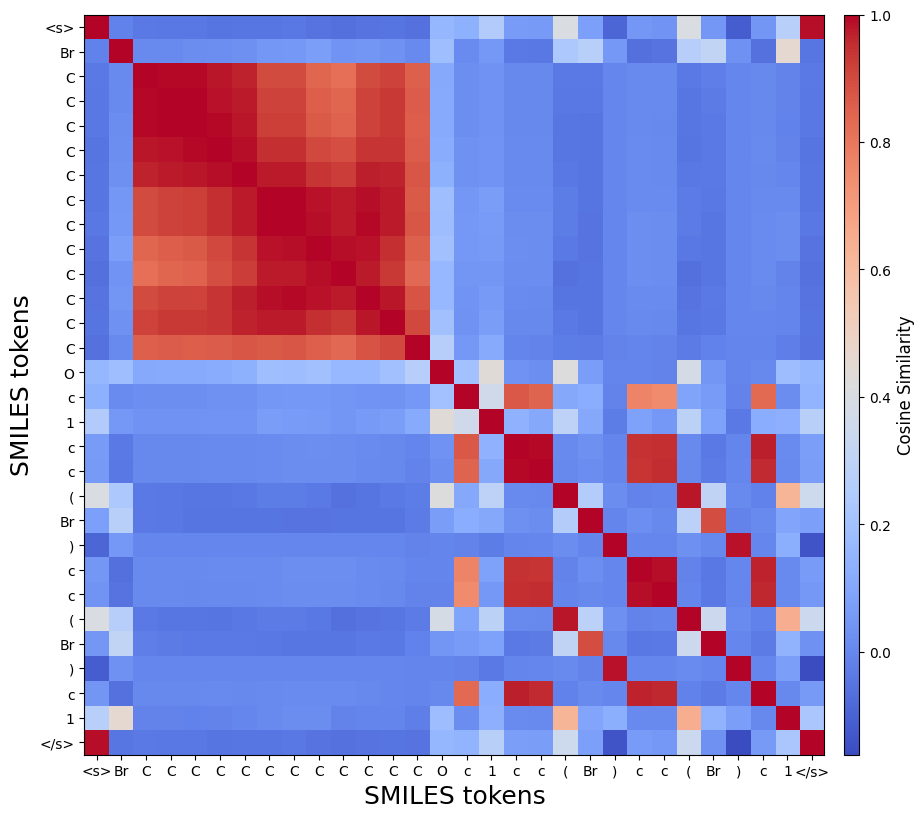

In [34]:
#  SMILES tokens and SMILES tokens cosine similarity
smi_esa_score = smiles_score[smiles_mask == 1]
smi_esa_score /= torch.norm(smi_esa_score, dim=1, keepdim=True)
token_peak_cos_similarity = smi_esa_score.cpu().numpy() @ smi_esa_score.cpu().numpy().T

smiles_token = get_tokenined_smiles(smiles, tokenizer, config_json)

plt.figure(figsize=(10, 10))

plt.xticks(range(len(smiles_token)), smiles_token, fontsize=10)
plt.yticks(range(len(smiles_token)), smiles_token, fontsize=10)

plt.xlabel('SMILES tokens', fontsize=18)
plt.ylabel('SMILES tokens', fontsize=18)

ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

# plt.savefig('fig/10_esa_smiles_smiles_heatmap_score_l2norm.png', dpi=300)
plt.show()

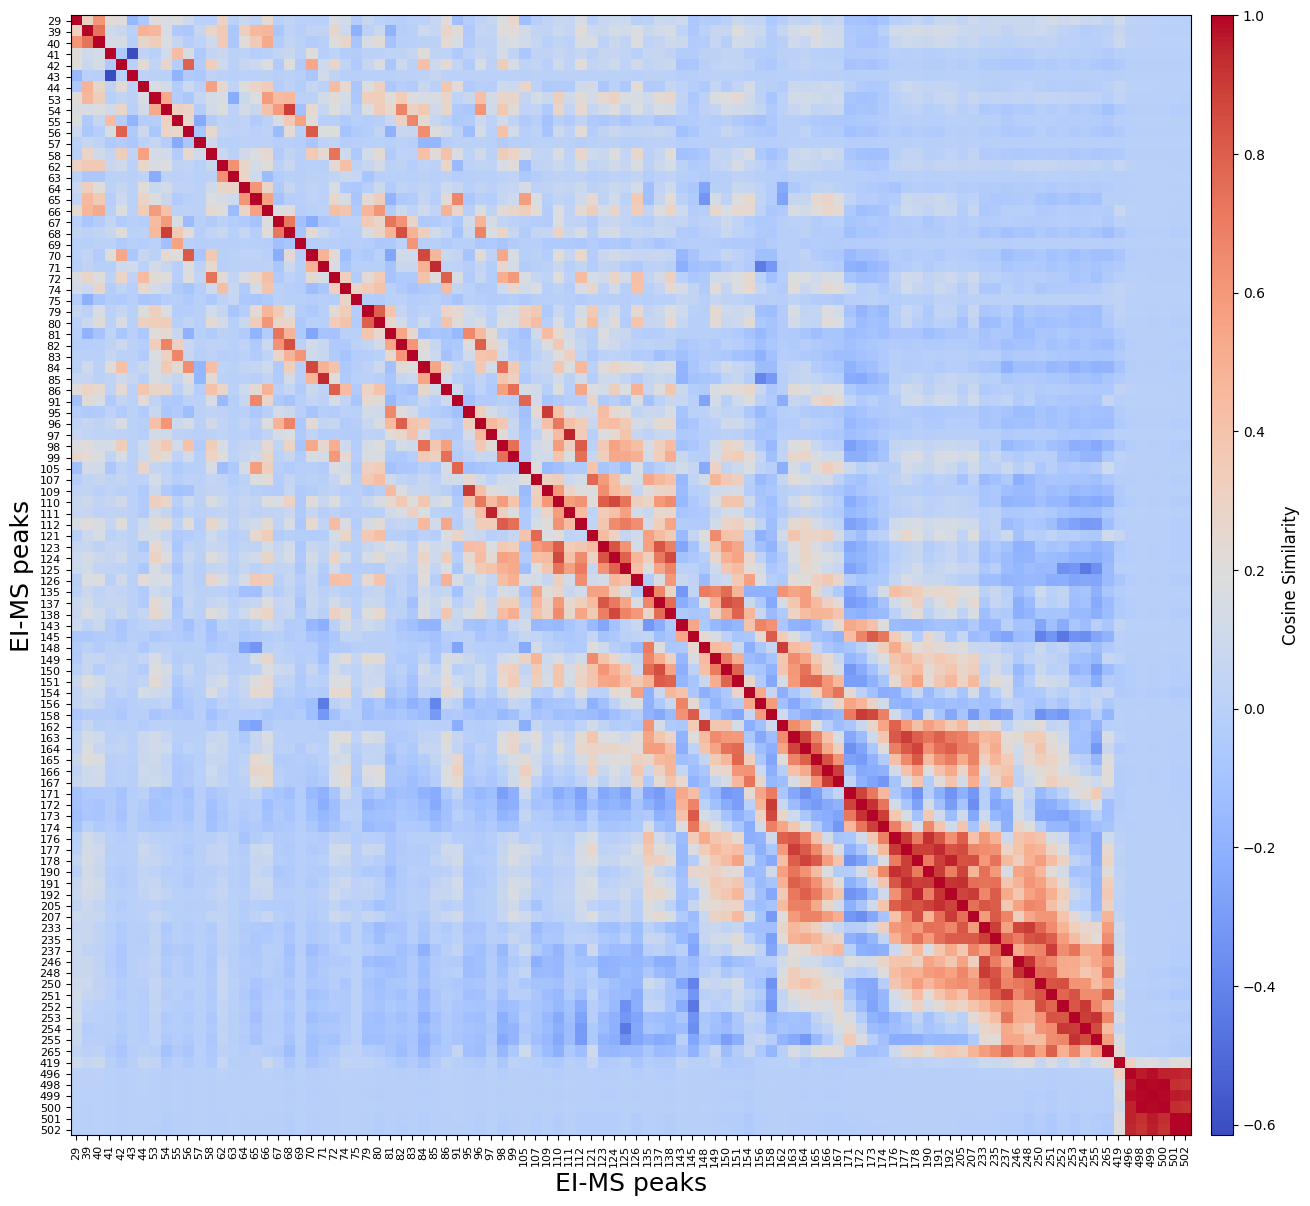

In [35]:
# EI-MS tokens and EI-MS tokens cosine similarity
ms_esa_score = ms_score[ms_mask == 1]
ms_esa_score /= torch.norm(ms_esa_score, dim=1, keepdim=True)
token_peak_cos_similarity = ms_esa_score.cpu().numpy() @ ms_esa_score.cpu().numpy().T

plt.figure(figsize=(15, 15))

plt.xticks(range(len(mz)), mz, fontsize=8, rotation=90)
plt.yticks(range(len(mz)), mz, fontsize=8)

plt.xlabel('EI-MS peaks', fontsize=18)
plt.ylabel('EI-MS peaks', fontsize=18)

ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

# plt.savefig('fig/10_esa_ms_ms_heatmap_score_l2norm.png', dpi=300)
plt.show()

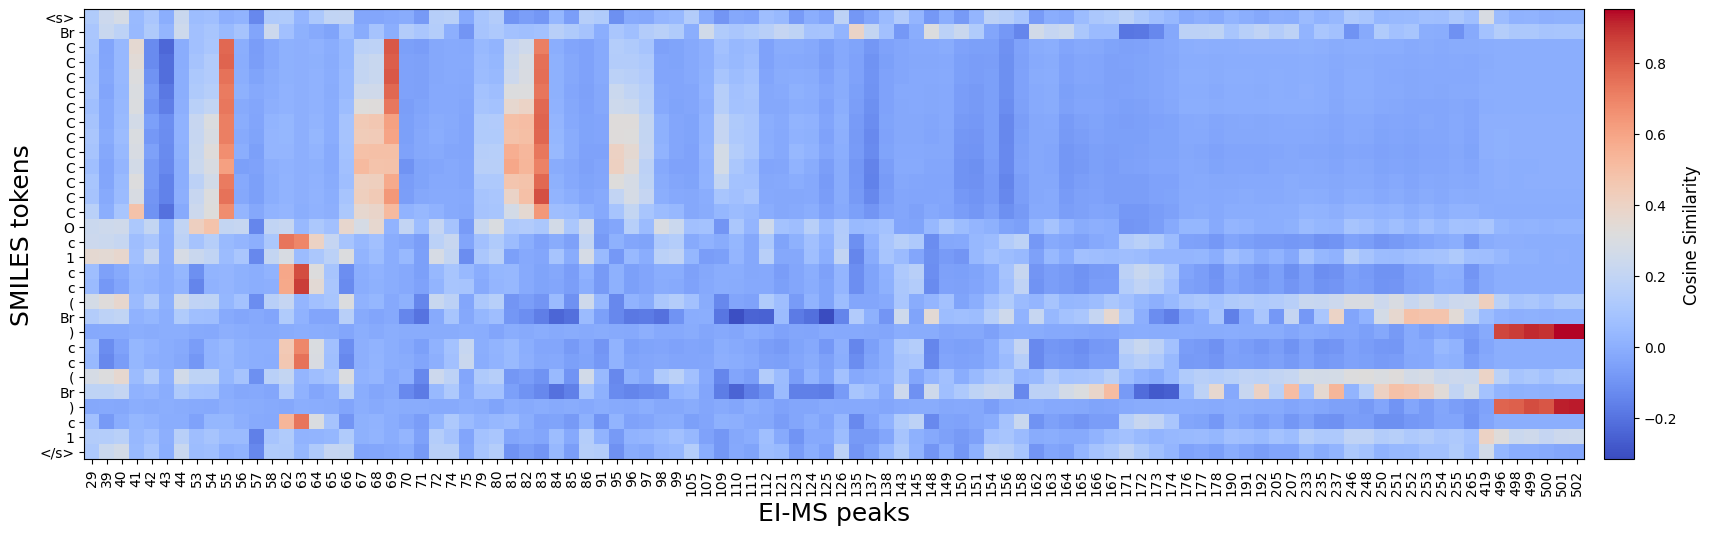

In [36]:
# SMILES tokens and EI-MS peaks cosine similarity

smiles_ids, smiles_mask = pre_processing_smi(smiles,tokenizer,config_json)
mz, intensity, ms_mask = pre_processing_ms(eims,config_json)
with torch.no_grad():
    model.eval()
    smiles_feature, smiles_score = model.smiles_encoder([smiles_ids, smiles_mask])
    ms_feature, ms_score = model.ms_encoder([mz, intensity, ms_mask])

smi_esa_score = smiles_score[smiles_mask == 1]
ms_esa_score = ms_score[ms_mask == 1]
smi_esa_score /= torch.norm(smi_esa_score, dim=1, keepdim=True)
ms_esa_score /= torch.norm(ms_esa_score, dim=1, keepdim=True)
token_peak_cos_similarity = smi_esa_score.cpu().numpy() @ ms_esa_score.cpu().numpy().T

mz = mz.squeeze(0).cpu().detach().numpy()[ms_mask.squeeze(0) == 1]
mz = mz.astype(int)
smiles_token = get_tokenined_smiles(smiles, tokenizer, config_json)

plt.figure(figsize=(20, 20))

# plt.imshow(token_peak_cos_similarity, cmap='GnBu', interpolation='nearest') 
# plt.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest') 

plt.xticks(range(len(mz)), mz, fontsize=10, rotation=90)
plt.yticks(range(len(smiles_token)), smiles_token, fontsize=10)

plt.xlabel('EI-MS peaks', fontsize=18)
plt.ylabel('SMILES tokens', fontsize=18)

ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

plt.savefig('fig/10_esa_smiles_ms_heatmap_score_l2norm.png', dpi=300)
plt.show()

# 4、Localization